# Breast Cancer Wisconsin — Diagnostic

### Context

Clinical imaging dataset describing breast masses using quantitative characteristics extracted from digitised images of fine-needle aspirates. The variables describe different morphological properties of cell nuclei.

### Dimensionality and Structure

The dataset contains 569 samples described by 30 continuous variables. Each sample is associated with a binary diagnosis: benign or malignant.


### Possible Questions
- Supervised learning: Predict whether a breast mass is benign or malignant.
- Unsupervised learning: Determine whether samples naturally separate into groups corresponding to benign and malignant diagnoses.
- Additional analysis: Identify the morphological variables that are the most discriminative.

In [19]:
### Imports

import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


In [20]:
### Chargement 

data = pd.read_csv("10_Breast_Cancer_Wisconsin_Diagnostic.csv")
print(data.shape)
data.head()

(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [21]:
from sklearn.preprocessing import StandardScaler

### Pré-traitements
print(data.columns)

### Supprimer colonne id
data = data.drop(['id'], axis=1)

### Binariser 'diagnosis'
data['diagnosis_num'] = data['diagnosis'].map({'M': 1, 'B': 0})

X_eda = data.drop(['diagnosis', 'diagnosis_num'], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_eda)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='str')


In [22]:
X_scaled

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

diagnosis_num              1.000000
concave_points_worst       0.793566
perimeter_worst            0.782914
concave_points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave_points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
symmetry_se               -0

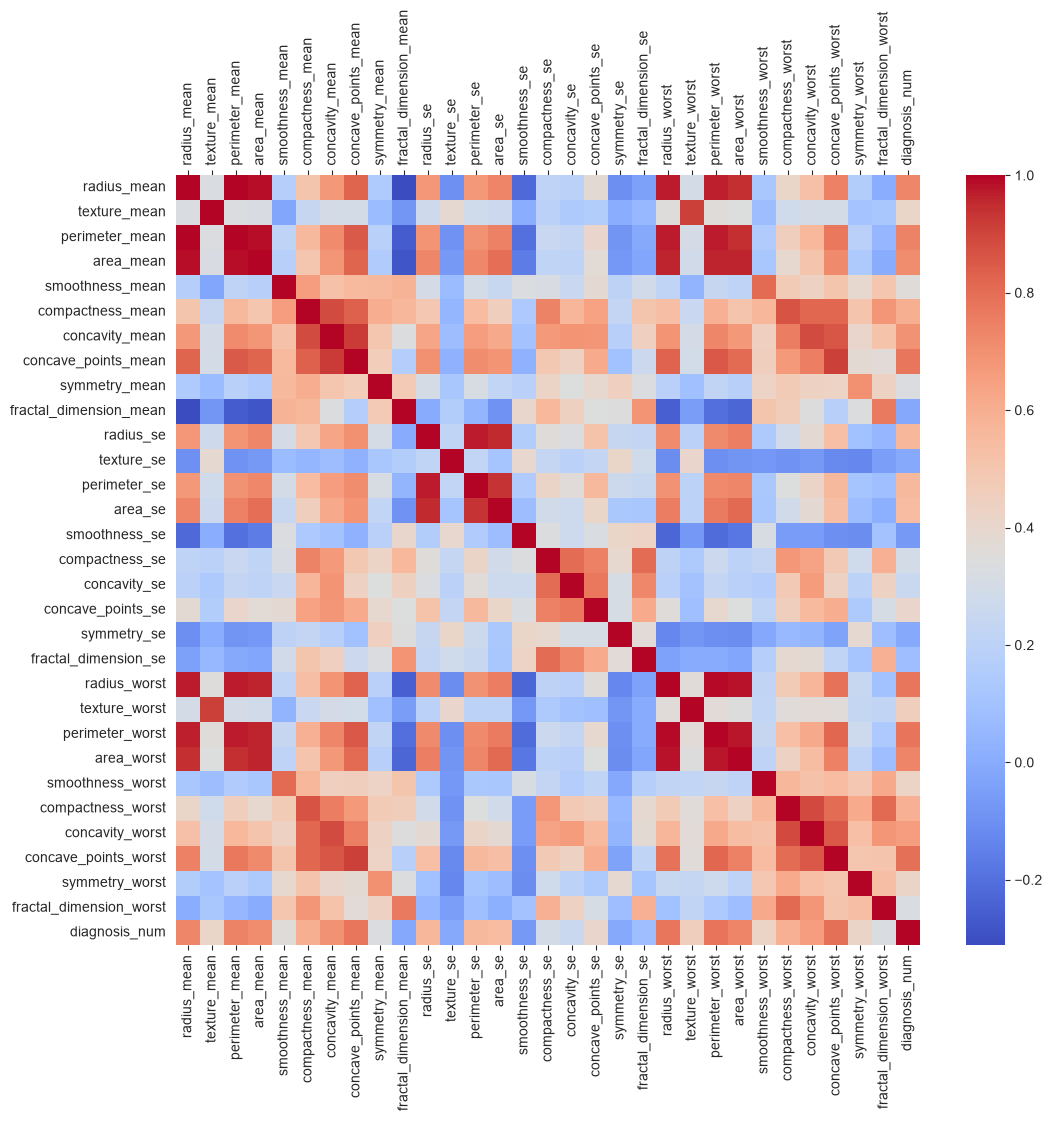

In [23]:
### Test corrélations
corr_matrix = data.select_dtypes(exclude=['object']).corr()
print(corr_matrix['diagnosis_num'].sort_values(ascending=False))

plt.figure(figsize=(12, 10))
ax = sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)

ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
plt.xticks(rotation=90)

plt.show()

In [24]:
### Feature selection
variables = [
    "perimeter_worst",
    ""
]

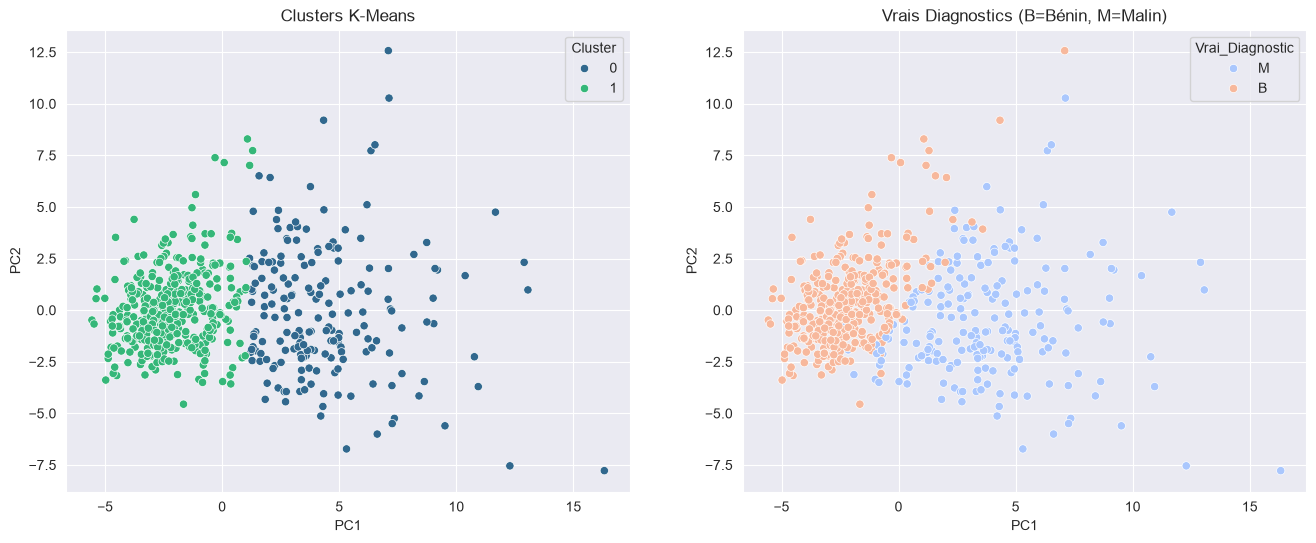

In [25]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(X_scaled)

df_viz = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_viz['Cluster'] = clusters
df_viz['Vrai_Diagnostic'] = data['diagnosis']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_viz, x='PC1', y='PC2', hue='Cluster', palette='viridis', ax=axes[0])
axes[0].set_title('Clusters K-Means')

sns.scatterplot(data=df_viz, x='PC1', y='PC2', hue='Vrai_Diagnostic', palette='coolwarm', ax=axes[1])
axes[1].set_title('Vrais Diagnostics (B=Bénin, M=Malin)')

plt.show()

In [30]:
### Séparation des données (Train/Test Split)